# 06 — MySQL testinin bütün test payload-larına genişləndirilməsi (4b)

05-də MySQL testi 300 payload üzərində aparılmışdı; effektiv çıxanlar cəmi ~19 unikal payload idi, ona görə
"semantika qorunur" və "MySQL-də keçən" faizləri az sayda hücuma əsaslanırdı. Bu notebook **test dəstinin bütün
zərərli payload-larını** eyni 10 kontekstdə yoxlayır və:
- **unikal effektiv payload** sayını (forma sayını yox) ayrıca göstərir,
- faizlər üçün **95% Wilson etibar intervalı** verir,
- effektiv payload-ları **hücum növünə** görə qruplaşdırır (boolean / union / error-based / time-based / stacked),
- `blacklist_vs_ml` cədvəlini bütün payload-larla yenidən qurur (köhnəsi `_n300` kimi saxlanılıb).

Təhlükəsizlik eyni qalır: `sqli_ml_eval` bazası, yalnız SELECT hüquqlu `sqli_eval` istifadəçisi, `max_execution_time = 2000` ms.

## 0. Mühit

In [1]:
import hashlib
import sys
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from urllib.parse import unquote

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymysql
from sklearn.metrics import confusion_matrix, f1_score, recall_score

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import obfuscation as obf
from blacklist import sanitize_input, sanitize_search

PROC_DIR = ROOT / "data" / "processed"
FIG_DIR, RES_DIR, MODEL_DIR = ROOT / "figures", ROOT / "results", ROOT / "models"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
save_fig = lambda fig, n: fig.savefig(FIG_DIR / n, dpi=300, bbox_inches="tight")

test = pd.read_csv(PROC_DIR / "test_v2.csv", keep_default_na=False, dtype={"Query": str, "Label": int})
malicious = test.loc[test.Label == 1, "Query"].reset_index(drop=True)
obf_A = pd.read_csv(PROC_DIR / "obfuscated_test_v2.csv", keep_default_na=False)
obf_A = obf_A[obf_A.scenario == "A"].reset_index(drop=True)
TECH_ORDER = list(obf.TECHNIQUES) + ["combination"]
VALID_TECHS = [t for t in TECH_ORDER if t != "keyword_split_comment"]

DETECTORS = {
    "Blacklist (Input)": lambda X: np.array([int(sanitize_input(q) != q) for q in X]),
    "Blacklist (Search)": lambda X: np.array([int(sanitize_search(q) != q) for q in X]),
}
for name, file in (("LR baseline", "lr_v2"), ("LR + normallaşdırma", "lr_norm_v2"),
                   ("LR + norm. + augmentation", "lr_norm_aug_v2")):
    DETECTORS[name] = joblib.load(MODEL_DIR / f"{file}.joblib").predict
print(f"Zərərli test payload-ları: {len(malicious)}")

Zərərli test payload-ları: 1745


## 1. Wilson etibar intervalı
Nisbətlər üçün 95% Wilson intervalı (normal approksimasiyadan kiçik n-lərdə daha dürüstdür).

In [2]:
from math import sqrt

def wilson(k, n, z=1.959963984540054):
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (p, max(0.0, centre - half), min(1.0, centre + half))

def wilson_str(k, n):
    p, lo, hi = wilson(k, n)
    return f"{p:.1%} [{lo:.1%}, {hi:.1%}] (n={n})"

print("Yoxlama:", wilson_str(155, 177))

Yoxlama: 87.6% [81.9%, 91.6%] (n=177)


## 2. MySQL icra mühiti (05-dəki eyni məntiq)
10 kontekst, zərərsiz imza ilə müqayisə. `fetchmany` 1000 sətirlə məhdudlaşır. Bağlantı itkisi icranı dayandırır.

In [3]:
def load_env(path):
    return dict(l.split("=", 1) for l in Path(path).read_text().splitlines() if "=" in l and not l.startswith("#"))

ENV = {k.strip(): v.strip() for k, v in load_env(ROOT / ".env").items()}
DB = dict(host="localhost", user=ENV["MYSQL_EVAL_USER"], password=ENV["MYSQL_EVAL_PASSWORD"],
          database="sqli_ml_eval", autocommit=True, read_timeout=15, write_timeout=15, connect_timeout=5)
CONTEXT_SQL = {
    "string": "SELECT * FROM products WHERE name = '{p}'",
    "numeric": "SELECT * FROM products WHERE id = {p}",
    "string_p1": "SELECT * FROM products WHERE (name = '{p}')",
    "string_p2": "SELECT * FROM products WHERE ((name = '{p}'))",
    "dquote": 'SELECT * FROM products WHERE name = "{p}"',
    "dquote_p1": 'SELECT * FROM products WHERE (name = "{p}")',
    "dquote_p2": 'SELECT * FROM products WHERE ((name = "{p}"))',
    "numeric_p1": "SELECT * FROM products WHERE (id = {p})",
    "numeric_p2": "SELECT * FROM products WHERE ((id = {p}))",
    "like": "SELECT * FROM products WHERE name LIKE '%{p}%'",
}
CONTEXTS = {n: (lambda tpl: (lambda p: tpl.replace("{p}", p)))(tpl) for n, tpl in CONTEXT_SQL.items()}
MAIN_CONTEXTS = ["string", "numeric"]
BENIGN = {c: "0" if c.startswith("numeric") else "zzz_benign" for c in CONTEXTS}
SYNTAX_ERRORS, LEAK_ERRORS, TIMEOUT = {1064, 1149}, {1105, 1062, 1690}, 3024
_local = threading.local()

def conn():
    c = getattr(_local, "conn", None)
    if c is None or not c.open:
        c = pymysql.connect(**DB)
        with c.cursor() as cur:
            cur.execute("SET SESSION max_execution_time = 2000")
        _local.conn = c
    return c

def run(sql):
    c = conn()
    t0 = time.perf_counter()
    try:
        with c.cursor() as cur:
            cur.execute(sql)
            rows = cur.fetchmany(1000)
        h = hashlib.sha1(repr(sorted(map(repr, rows))).encode()).hexdigest()[:12]
        status, code = "ok", 0
    except pymysql.MySQLError as e:
        code = e.args[0] if e.args and isinstance(e.args[0], int) else -1
        status = ("syntax_error" if code in SYNTAX_ERRORS else "timeout" if code == TIMEOUT
                  else "conn_lost" if code in (2006, 2013) else "error")
        h = None
        if status == "conn_lost":
            _local.conn = None
    return {"status": status, "code": code, "rows_hash": h, "slow": time.perf_counter() - t0 >= 1.0}

with conn().cursor() as cur:
    cur.execute("SHOW GRANTS")
    grants = " ".join(g[0] for g in cur.fetchall()).upper()
assert not any(p in grants for p in ("ALL PRIVILEGES", "INSERT", "UPDATE", "DELETE", "DROP", "FILE"))
print("Test istifadəçisi yalnız SELECT:", "SELECT ON `SQLI_ML_EVAL`" in grants)

Test istifadəçisi yalnız SELECT: True


## 3. İcra: bütün zərərli payload-lar
Hər payload üçün: orijinal + ssenari A obfuskasiyaları + hər formanın `sanitizeInput`/`sanitizeSearch` versiyası.
Unikal `(kontekst, mətn)` cütləri bir dəfə icra olunur.

In [4]:
variants = [(i, "original", malicious[i]) for i in range(len(malicious))]
variants += [(r.index, r.technique, r.model_input) for r in obf_A.itertuples()]
var_df = pd.DataFrame(variants, columns=["payload_id", "variant", "text"])
var_df["text_san_input"] = var_df.text.map(sanitize_input)
var_df["text_san_search"] = var_df.text.map(sanitize_search)
print(f"{len(malicious)} payload → {len(var_df)} forma (orijinal + obfuskasiya)")

texts = pd.unique(pd.concat([var_df.text, var_df.text_san_input, var_df.text_san_search,
                             pd.Series(["zzz_benign", "0"])]))
jobs = [(c, t) for c in CONTEXTS for t in texts]
print(f"Unikal icra: {len(jobs):,}")
t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as ex:
    sigs = list(ex.map(lambda j: run(CONTEXTS[j[0]](j[1])), jobs))
SIG = dict(zip(jobs, sigs))
print(f"MySQL icrası: {time.perf_counter() - t0:.0f} s")

1745 payload → 18900 forma (orijinal + obfuskasiya)


Unikal icra: 398,730


MySQL icrası: 211 s


In [5]:
def key(s):
    return (s["status"], s["code"] if s["status"] == "error" else 0, s["rows_hash"], s["slow"])

def effective(s, ctx):
    if s["status"] in ("syntax_error", "conn_lost"):
        return False
    if s["status"] == "timeout" or s["slow"]:
        return True
    if s["status"] == "error":
        return s["code"] in LEAK_ERRORS
    return key(s) != key(SIG[(ctx, BENIGN[ctx])])

for ctx in CONTEXTS:
    for col, src in (("", "text"), ("_san_input", "text_san_input"), ("_san_search", "text_san_search")):
        s = var_df[src].map(lambda t: SIG[(ctx, t)])
        var_df[f"{ctx}_parses{col}"] = s.map(lambda x: x["status"] not in ("syntax_error", "conn_lost"))
        var_df[f"{ctx}_effective{col}"] = s.map(lambda x: effective(x, ctx))
        var_df[f"{ctx}_key{col}"] = s.map(key)

var_df["parses"] = var_df[[f"{c}_parses" for c in CONTEXTS]].any(axis=1)
var_df["effective"] = var_df[[f"{c}_effective" for c in CONTEXTS]].any(axis=1)
var_df["effective_main"] = var_df[[f"{c}_effective" for c in MAIN_CONTEXTS]].any(axis=1)
for san in ("input", "search"):
    var_df[f"survives_{san}"] = np.zeros(len(var_df), dtype=bool)
    for ctx in CONTEXTS:
        var_df[f"survives_{san}"] |= var_df[f"{ctx}_effective"] & (var_df[f"{ctx}_key"] == var_df[f"{ctx}_key_san_{san}"])

orig = var_df[var_df.variant == "original"].set_index("payload_id")
k_eff = int(orig.effective.sum())
print(f"Orijinal payload-lar: n={len(orig)}, effektiv (hər hansı kontekst) = {wilson_str(k_eff, len(orig))}")
print(f"  yalnız string/numeric: {wilson_str(int(orig.effective_main.sum()), len(orig))}")
var_df.drop(columns=[c for c in var_df.columns if c.endswith("_key") or "_key_" in c]).to_csv(
    PROC_DIR / "06_mysql_effectiveness.csv", index=False)

Orijinal payload-lar: n=1745, effektiv (hər hansı kontekst) = 6.4% [5.3%, 7.6%] (n=1745)
  yalnız string/numeric: 2.1% [1.5%, 2.9%] (n=1745)


## 4. Effektiv payload-ların hücum növü
Orijinal payload mətninə görə təsnifat (prioritet sırası: stacked → time-based → error-based → union → boolean → digər).
Təsnifat payload-ın niyyətinə görədir; "effektiv" yalnız bu laborator sxemdə icra effekti verənlər üçün hesablanır.

In [6]:
import re
ATTACK_PATTERNS = [
    ("stacked", r";\s*(select|insert|update|delete|drop|create|exec|declare|waitfor|shutdown)\b"),
    ("time-based", r"\b(sleep|benchmark|pg_sleep|waitfor\s+delay|generate_series|dbms_pipe\.receive_message)\b"),
    ("error-based", r"\b(extractvalue|updatexml|exp\s*\(|floor\s*\(\s*rand|dbms_pipe|utl_inaddr|ctxsys)\b|0x7171"),
    ("union", r"\bunion\b"),
    ("boolean", r"\b(or|and|rlike|like)\b|=\s*\d|\bexists\b"),
]
def attack_type(q):
    ql = q.lower()
    for name, pat in ATTACK_PATTERNS:
        if re.search(pat, ql):
            return name
    return "digər"

orig = orig.copy()
orig["attack_type"] = orig.text.map(attack_type)
eff = orig[orig.effective]
by_type = pd.DataFrame({
    "effektiv payload": eff.attack_type.value_counts(),
    "test dəstindəki payload": orig.attack_type.value_counts(),
})
by_type["effektivlik %"] = (by_type["effektiv payload"] / by_type["test dəstindəki payload"] * 100).round(1)
by_type = by_type.fillna(0).astype({"effektiv payload": int, "test dəstindəki payload": int})
by_type.loc["CƏMI"] = [by_type["effektiv payload"].sum(), by_type["test dəstindəki payload"].sum(),
                       round(eff.shape[0] / orig.shape[0] * 100, 1)]
by_type.to_csv(RES_DIR / "06_attack_types.csv")
display(by_type)
print(f"Unikal effektiv payload: {len(eff)} / {len(orig)}")

,effektiv payload,test dəstindəki payload,effektivlik %
attack_type,,,
boolean,23,874,2.6
digər,3,47,6.4
error-based,38,158,24.1
stacked,0,2,0.0
time-based,41,324,12.7
union,6,340,1.8
CƏMI,111,1745,6.4


Unikal effektiv payload: 111 / 1745


## 5. Obfuskasiya semantikanı saxlayırmı? (unikal payload + Wilson CI)
Baza: orijinalı effektiv olan payload-lar. Hər texnika üçün: obfuskasiya olunmuş forma hələ parse olunur və imzası
orijinalınkı ilə eynidir (hər hansı kontekstdə). İndi həm **forma** sayı, həm də **unikal payload** sayı göstərilir.

In [7]:
eff_ids = set(orig[orig.effective].index)
sem_rows = []
for tech in TECH_ORDER:
    sub = var_df[(var_df.variant == tech) & var_df.payload_id.isin(eff_ids)].copy()
    sub = sub.merge(orig[["effective"]], left_on="payload_id", right_index=True, suffixes=("", "_o"))
    if sub.empty:
        continue
    same = np.zeros(len(sub), dtype=bool)
    for ctx in CONTEXTS:
        o_key = sub.payload_id.map(orig[f"{ctx}_key"]); o_eff = sub.payload_id.map(orig[f"{ctx}_effective"])
        same |= o_eff.to_numpy() & (sub[f"{ctx}_key"].to_numpy() == o_key.to_numpy())
    sub["preserved"] = same
    k, n = int(same.sum()), len(sub)
    up = sub.loc[same, "payload_id"].nunique()
    p, lo, hi = wilson(k, n)
    sem_rows.append({"technique": tech, "forms": n, "preserved_forms": k, "unique_payloads": sub.payload_id.nunique(),
                     "preserved_unique_payloads": up, "preserved_pct": round(p * 100, 1),
                     "ci_low": round(lo * 100, 1), "ci_high": round(hi * 100, 1)})
semantics = pd.DataFrame(sem_rows).set_index("technique")
semantics.to_csv(RES_DIR / "06_obfuscation_semantics.csv")
display(semantics)

pooled = var_df[var_df.variant.isin(VALID_TECHS) & var_df.payload_id.isin(eff_ids)]
same = np.zeros(len(pooled), dtype=bool)
for ctx in CONTEXTS:
    o_key = pooled.payload_id.map(orig[f"{ctx}_key"]); o_eff = pooled.payload_id.map(orig[f"{ctx}_effective"])
    same |= o_eff.to_numpy() & (pooled[f"{ctx}_key"].to_numpy() == o_key.to_numpy())
print(f"Ümumi (keyword_split_comment xaric): semantika qorunur = {wilson_str(int(same.sum()), len(same))}")
print(f"  bu, {pooled.loc[same, 'payload_id'].nunique()} unikal effektiv payload-a aiddir")

,forms,preserved_forms,unique_payloads,preserved_unique_payloads,preserved_pct,ci_low,ci_high
technique,,,,,,,
random_case,109,109,109,109,100.0,96.6,100.0
inline_comment_space,109,107,109,107,98.2,93.6,99.5
alt_whitespace,109,108,109,108,99.1,95.0,99.8
alt_whitespace_url,109,105,109,105,96.3,90.9,98.6
url_encode,110,110,110,110,100.0,96.6,100.0
double_url_encode,110,0,110,0,0.0,0.0,3.4
versioned_comment,109,109,109,109,100.0,96.6,100.0
logical_operator,94,94,94,94,100.0,96.1,100.0
hex_strings,57,57,57,57,100.0,93.7,100.0


Ümumi (keyword_split_comment xaric): semantika qorunur = 85.9% [83.6%, 87.9%] (n=1026)
  bu, 110 unikal effektiv payload-a aiddir


## 6. Birinci məqalənin filtri real MySQL-də (unikal payload + Wilson CI)

In [8]:
san_rows = []
for label, sub in (("orijinal", var_df[var_df.variant == "original"]),
                   ("obfuskasiya (A, etibarlı texnikalar)", var_df[var_df.variant.isin(VALID_TECHS)])):
    e = sub[sub.effective]
    for san in ("input", "search"):
        k = int(e[f"survives_{san}"].sum()); n = len(e)
        up = e.loc[e[f"survives_{san}"], "payload_id"].nunique()
        p, lo, hi = wilson(k, n)
        san_rows.append({"payloads": label, "sanitizer": f"sanitize{san.capitalize()}()", "n_effective_forms": n,
                         "survives_forms": k, "survives_unique_payloads": up,
                         "survives_pct": round(p * 100, 1), "ci_low": round(lo * 100, 1), "ci_high": round(hi * 100, 1),
                         "neutralized_pct": round((1 - p) * 100, 1)})
sanitizer_mysql = pd.DataFrame(san_rows)
sanitizer_mysql.to_csv(RES_DIR / "06_sanitizer_mysql.csv", index=False)
display(sanitizer_mysql)

,payloads,sanitizer,n_effective_forms,survives_forms,survives_unique_payloads,survives_pct,ci_low,ci_high,neutralized_pct
0,orijinal,sanitizeInput(),111,3,3,2.7,0.9,7.6,97.3
1,orijinal,sanitizeSearch(),111,21,21,18.9,12.7,27.2,81.1
2,"obfuskasiya (A, etibarlı texnikalar)",sanitizeInput(),885,27,19,3.1,2.1,4.4,96.9
3,"obfuskasiya (A, etibarlı texnikalar)",sanitizeSearch(),885,102,21,11.5,9.6,13.8,88.5


## 7. Əsas cədvəl (bütün payload-lar)
`mysql_executed_not_blocked`: bütün effektiv forma (orijinal + etibarlı obfuskasiya) arasında bazada işləyib
detektordan keçənlər. Həm forma sayı, həm unikal payload sayı, keçmə faizi üçün Wilson CI.

In [9]:
det_table = pd.read_csv(RES_DIR / "05_detector_table.csv", index_col="detector")  # recall/FPR bütün test dəstində, dəyişmir
pool = var_df[var_df.variant.isin(["original"] + VALID_TECHS) & var_df.effective].copy()
rows = []
for name in DETECTORS:
    worst = min(VALID_TECHS, key=lambda t: det_table.loc[name, f"recall_A_{t}"])
    if name.startswith("Blacklist"):
        passed = pool[f"survives_{'input' if 'Input' in name else 'search'}"].to_numpy()
    else:
        passed = DETECTORS[name](pool.text) == 0
    k, n = int(passed.sum()), len(pool)
    p, lo, hi = wilson(k, n)
    rows.append({"detector": name, "recall_original": det_table.loc[name, "recall"],
                 "fpr_original": det_table.loc[name, "fpr"], "fpr_plain_input": det_table.loc[name, "fpr_plain_input"],
                 "f1_original": det_table.loc[name, "f1"], "worst_technique": worst,
                 "worst_obfuscation_recall": det_table.loc[name, f"recall_A_{worst}"],
                 "mysql_effective_forms": n, "mysql_passed_forms": k,
                 "mysql_passed_unique_payloads": int(pd.Series(passed, index=pool.index).groupby(pool.payload_id).any().sum()),
                 "mysql_passed_pct": round(p * 100, 2), "ci_low": round(lo * 100, 2), "ci_high": round(hi * 100, 2)})
main = pd.DataFrame(rows).set_index("detector")
main.to_csv(RES_DIR / "blacklist_vs_ml.csv")
display(main[["recall_original", "fpr_original", "fpr_plain_input", "worst_obfuscation_recall",
              "mysql_effective_forms", "mysql_passed_forms", "mysql_passed_unique_payloads", "mysql_passed_pct"]])
print(f"\nEffektiv formalar hovuzu: {len(pool)} forma, {pool.payload_id.nunique()} unikal payload")

,recall_original,fpr_original,fpr_plain_input,worst_obfuscation_recall,mysql_effective_forms,mysql_passed_forms,mysql_passed_unique_payloads,mysql_passed_pct
detector,,,,,,,,
Blacklist (Input),0.975931,0.648533,0.123214,0.913793,996,30,20,3.01
Blacklist (Search),0.949570,0.599141,0.017857,0.712644,996,123,22,12.35
LR baseline,0.995989,0.001074,0.001786,0.777714,996,46,23,4.62
LR + normallaşdırma,0.994842,0.001432,0.001786,0.997701,996,1,1,0.10
LR + norm. + augmentation,0.993696,0.000716,0.000893,0.996552,996,1,1,0.10



Effektiv formalar hovuzu: 996 forma, 114 unikal payload


Qrafik: hücum növünə görə effektiv payload-lar və detektorların keçirdiyi payload sayı.

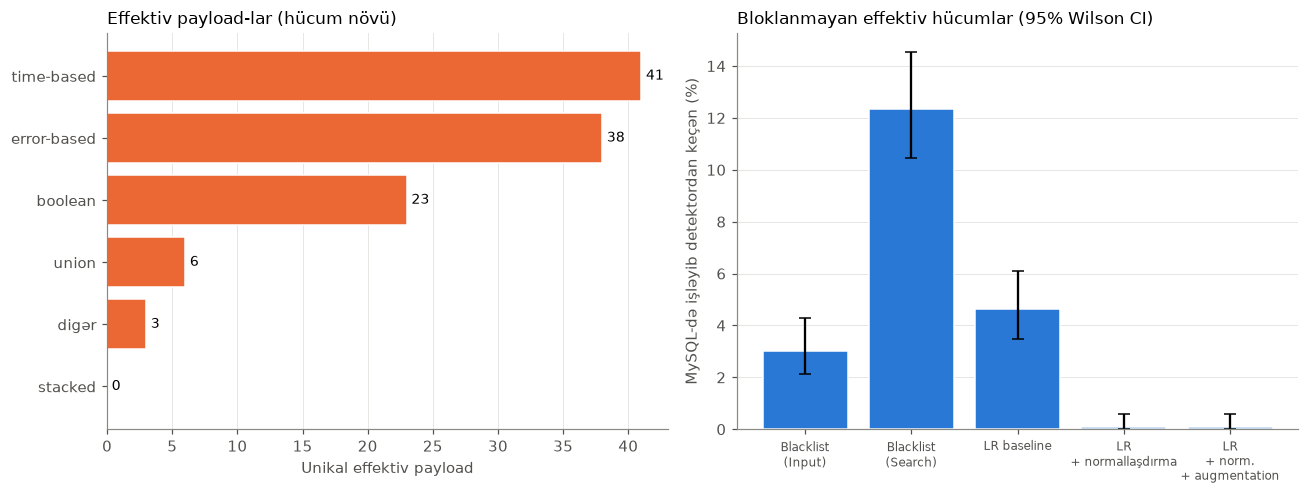

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
bt = by_type.drop(index="CƏMI").sort_values("effektiv payload", ascending=True)
ax1.barh(bt.index, bt["effektiv payload"], color="#eb6834", edgecolor="white", linewidth=1)
for y, v in enumerate(bt["effektiv payload"]):
    ax1.annotate(str(v), (v, y), xytext=(3, 0), textcoords="offset points", va="center", fontsize=9)
ax1.set_title("Effektiv payload-lar (hücum növü)", loc="left", fontsize=11)
ax1.set_xlabel("Unikal effektiv payload")
ax1.grid(axis="y", visible=False)

order = ["Blacklist (Input)", "Blacklist (Search)", "LR baseline", "LR + normallaşdırma", "LR + norm. + augmentation"]
vals = main.loc[order, "mysql_passed_pct"]
err = [vals - main.loc[order, "ci_low"], main.loc[order, "ci_high"] - vals]
ax2.bar(range(len(order)), vals, yerr=err, capsize=4, color="#2a78d6", edgecolor="white", linewidth=1)
ax2.set_xticks(range(len(order)), [o.replace(" + ", "\n+ ").replace(" (", "\n(") for o in order], fontsize=8)
ax2.set_ylabel("MySQL-də işləyib detektordan keçən (%)")
ax2.set_title("Bloklanmayan effektiv hücumlar (95% Wilson CI)", loc="left", fontsize=11)
ax2.grid(axis="x", visible=False)
fig.tight_layout()
save_fig(fig, "06_attack_types_and_bypass.png")
plt.show()